# Tutorial 04: 1D or 2D
This notebook will guide you through the choice between a 1D and a 2D model of the column.
You will learn how to:
- turn the same case from 2D into 1D with one setting;
- switch on wall channeling (the looser packing next to the wall);
- run the three models to their periodic state and compare their KPIs;
- see what a 1D model cannot see: the hot layer at the wall.

The two models:
- **1D**: along the axis only.
  - Every cross-section is uniform.
  - The wall exchanges heat with it through a heat transfer coefficient.
- **2D**: along the axis and across the radius.
  - It resolves how heat and gas move between the wall and the axis.

### Overview
- **Case:** [`../cases/04_1d_vs_2d.json`](../cases/04_1d_vs_2d.json):
  the built-in defaults on a 2D grid of 50 axial by 40 radial cells, every step stopped on time.
- **Runtime:** three CSS runs, about 2 minutes in 1D and about 20 minutes for each 2D run; about 1.5 GB on disk.
  - Why so long: a 2D run solves the whole column at once: 50 × 40 = 2000 cells with 7 unknowns each, plus the wall, that is 14 055 equations at every time step, against 405 for the same column in 1D.
  - So start the runs when you can leave them going. The times were measured on a workstation; on a laptop expect longer.
- **Same tutorial without a notebook:** the terminal commands at the end.

A note on the grid:
- All three runs use the same grid along the column, so their differences do not come from the axial resolution.
- This is not a grid-independence study.

### Before you start
1. Install pyDAC and select its kernel, as in [tutorial 01](01_first_steps.ipynb).
2. Read [tutorial 03](03_css_tvsa.ipynb) first: here we use its KPIs and plots.
3. Run the cells in order, from the top.

The results are written under `simulation_results/`, next to this notebook.

In [1]:
# Import necessary libraries
import pickle
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

import pydac
from pydac.utils.postprocessing.saved_solution import saved_solution_view

# The case file of this tutorial
CASE = Path("../cases/04_1d_vs_2d.json")

## The case and its three variants

We use the built-in cycle of tutorials [01](01_first_steps.ipynb) and [03](03_css_tvsa.ipynb), on a 50 x 40 grid.\
Three options matter here:

**1. `execution.termination_mode = "time"`**: every step runs for its fixed time (`horizon.nominal_time_s`).
- By default `blow`, `cool` and `press` stop at an event.
- That would end them at different times in the three models.
- On time, all three runs have the same cycle, step by step.

**2. `execution.keep_only_final_cycle = true`**: each run keeps only the folder of its reported cycle.

**3. `execution.print_to_terminal = false`** (and `print_cycle_build = false`):
- Three CSS runs would print many thousands of lines: too cluttered to read.
- Tutorials [02](02_custom_case.ipynb) and [03](03_css_tvsa.ipynb) keep it on, to show you what the log looks like.
- The log is still written: `log.txt` in each run folder (under `1D_mode/` or `2D_mode/`).


In [2]:
# Show the preset
print(CASE.read_text())

{
  "schema_version": 8,
  "simulation": {
    "grid": {
      "nz": 50,
      "nr": 40
    }
  },
  "execution": {
    "termination_mode": "time",
    "plot_final_cycle_profiles": true,
    "keep_only_final_cycle": true,
    "plot_format": "png",
    "print_to_terminal": false,
    "print_cycle_build": false,
    "extra_tag": "tutorial_04"
  }
}



The other two cases start from the same file, with one change each. We pass each change as `settings` to `load_case()` (see [Tutorial 02](02_custom_case.ipynb)):
- `grid.nr = 1` gives the **1D** model;
- `bed.design.flow_model = "wall-channeling-reduced"` gives the **2D model with channeling**:
  - a radial voidage profile (de Klerk's correlation by default);
  - the gas flows faster where the packing is looser.

Each run also draws the bed temperature in `heat`, map and 1D profiles, at the same six times\
(`snapshot_times`, as in [Tutorial 03](03_css_tvsa.ipynb)): the figures of the three runs show the same instants.

In [3]:
# The three cases: the file as it is, and two variants with one setting each
cases = {
    "2D": pydac.load_case(CASE),
    "1D": pydac.load_case(CASE, settings={"grid.nr": 1}),
    "2D, channeling": pydac.load_case(CASE, settings={"bed.design.flow_model": "wall-channeling-reduced"}),
}

# The times of the map of the bed temperature in `heat`, the same for the three runs (figures only)
snapshot_times = {"heat": {"T_bed": {"times": [1, 5, 10, 20, 30, 150], "unit": "min"}}}

# Run each one to CSS (one after the other) and print where it stopped
results = {name: pydac.run_css(case, overwrite=True, snapshot_times=snapshot_times) for name, case in cases.items()}
for name, result in results.items():
    print(f"{name:15s} CSS at cycle {result.cycle}: {result.folder.name}")

Overwrite: deleted /path/to/pyDAC/examples/notebooks/simulation_results/cyclic_mode/tutorial_04_packed_bed_bc77c79c
Run folder: /path/to/pyDAC/examples/notebooks/simulation_results/cyclic_mode/tutorial_04_packed_bed_bc77c79c
Post-processing cycle 3.
[CyclicProfiles] Mixed-cup outlet average had zero denominator; falling back to radial average for those points.
[Saved] simulation_results/cyclic_mode/tutorial_04_packed_bed_bc77c79c/2D_mode/plots_css/cycle_3/css_outlet_y_CO2.png
[Saved] simulation_results/cyclic_mode/tutorial_04_packed_bed_bc77c79c/2D_mode/plots_css/cycle_3/css_outlet_y_H2O.png
[Saved] simulation_results/cyclic_mode/tutorial_04_packed_bed_bc77c79c/2D_mode/plots_css/cycle_3/css_outlet_y_O2.png
[Saved] simulation_results/cyclic_mode/tutorial_04_packed_bed_bc77c79c/2D_mode/plots_css/cycle_3/css_outlet_y_N2.png
[Saved] simulation_results/cyclic_mode/tutorial_04_packed_bed_bc77c79c/2D_mode/plots_css/cycle_3/css_outlet_q_CO2.png
[Saved] simulation_results/cyclic_mode/tutorial_0

## Let's compare the predictions of the different models

We extract the same KPIs as in [tutorial 03](03_css_tvsa.ipynb), plus two more:
- the CO2 that leaves during wall heating (vented);
- the coldest point of the bed at the end of `heat`.

In [4]:
def cycle_kpis(result):
    # The KPIs of the reported cycle of one run
    kpis = pydac.CycleKPIs(pydac.CycleDataLoader(result.folder).load())
    return {
        "productivity [kg/m3/day]": kpis.productivity(),
        "equivalent work [kWh/kg]": kpis.equivalent_work() / 3.6,
        "steam / CO2 [kg/kg]": kpis.steam_to_co2_ratio(),
        "CO2 recovery [%]": 100 * kpis.recovery(),
        "CO2 adsorbed [g]": 1000 * kpis.mass_change_table()["CO2"]["adsorption"],
        "CO2 vented in heat [g]": 1000 * kpis.vented_mass(),
        "CO2 recovered [g]": 1000 * kpis.recovered_mass("CO2"),
        "coldest bed point after heat [°C]": kpis.preheating_temperatures()["bed_minimum_K"] - 273.15,
    }


# One column per model, plus the relative differences against 2D
table = pd.DataFrame({name: cycle_kpis(result) for name, result in results.items()})
table["1D vs 2D [%]"] = 100 * (table["1D"] / table["2D"] - 1)
table["channeling vs 2D [%]"] = 100 * (table["2D, channeling"] / table["2D"] - 1)
# A relative change of a temperature in °C means nothing: compare those in the columns.
table.loc["coldest bed point after heat [°C]", ["1D vs 2D [%]", "channeling vs 2D [%]"]] = float("nan")
table.round(2)

,2D,1D,"2D, channeling",1D vs 2D [%],channeling vs 2D [%]
productivity [kg/m3/day],26.15,29.63,25.96,13.30,-0.74
equivalent work [kWh/kg],24.36,21.44,24.53,-11.99,0.70
steam / CO2 [kg/kg],194.74,171.87,196.20,-11.74,0.75
CO2 recovery [%],65.88,74.65,66.84,13.31,1.45
CO2 adsorbed [g],28.06,28.06,27.45,-0.00,-2.16
CO2 vented in heat [g],6.89,4.39,6.41,-36.24,-6.99
CO2 recovered [g],18.49,20.95,18.35,13.30,-0.74
coldest bed point after heat [°C],69.22,79.48,69.26,NaN,NaN


## 1D against 2D

What the table tells us:
- **Adsorption**: both models adsorb the same CO2, about 28 g per cycle.
  - During adsorption the cross-section of this column stays nearly uniform.
- **Wall heating**: here the two models part.
  - The 1D model predicts about 13 % more productivity.
  - And 12 % less equivalent work and steam per kg of CO2.
- **Why?** The 1D model vents about a third less CO2 during `heat` (4.4 g against 6.9 g).
  - It recovers that CO2 in `s_des` instead.

The bed temperature during `heat` shows why: 
- first the 2D map, 
- then the 1D profiles,
- finally both at mid-height, across the radius: the 2D profile against the one value of the 1D model.

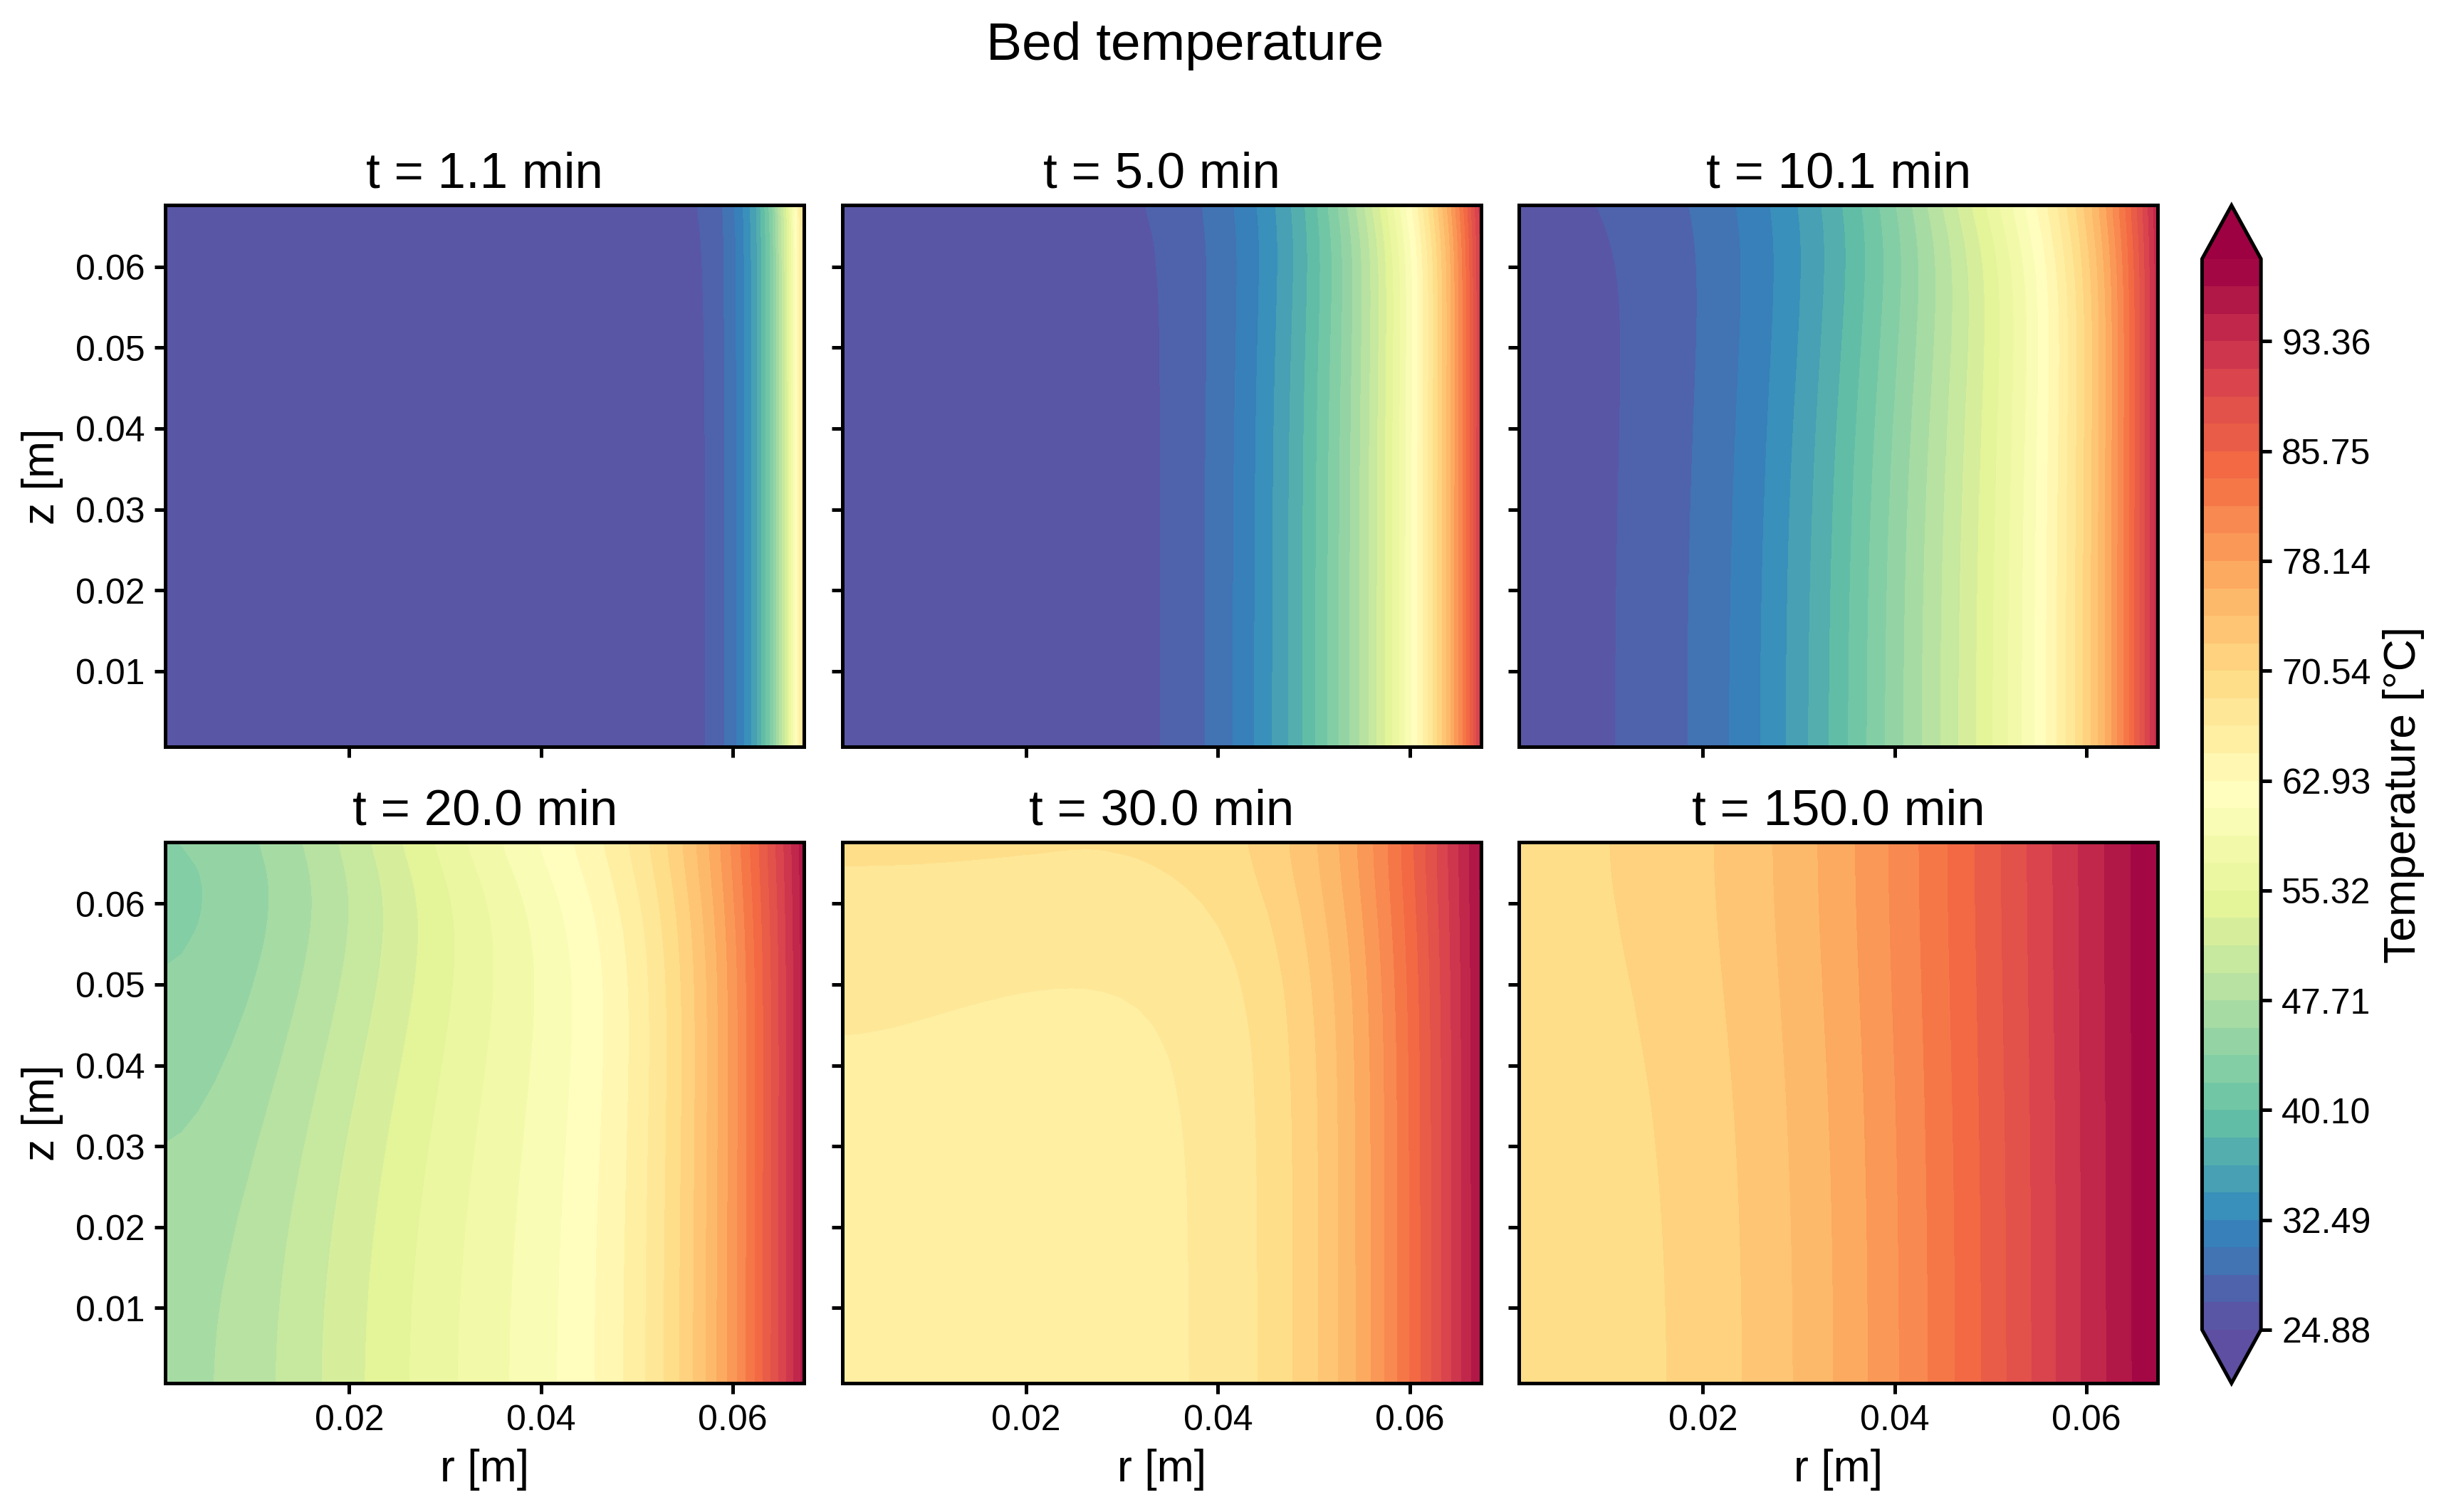

In [5]:
# Bed temperature during `heat` in the reported cycle, 2D model
heat_map = "heat/profiles/internal_2D_profiles/heat_Tbed_2D_snapshots.png"
display(Image(filename=results["2D"].results_folder / f"cycle_{results['2D'].cycle}" / heat_map, width=700))

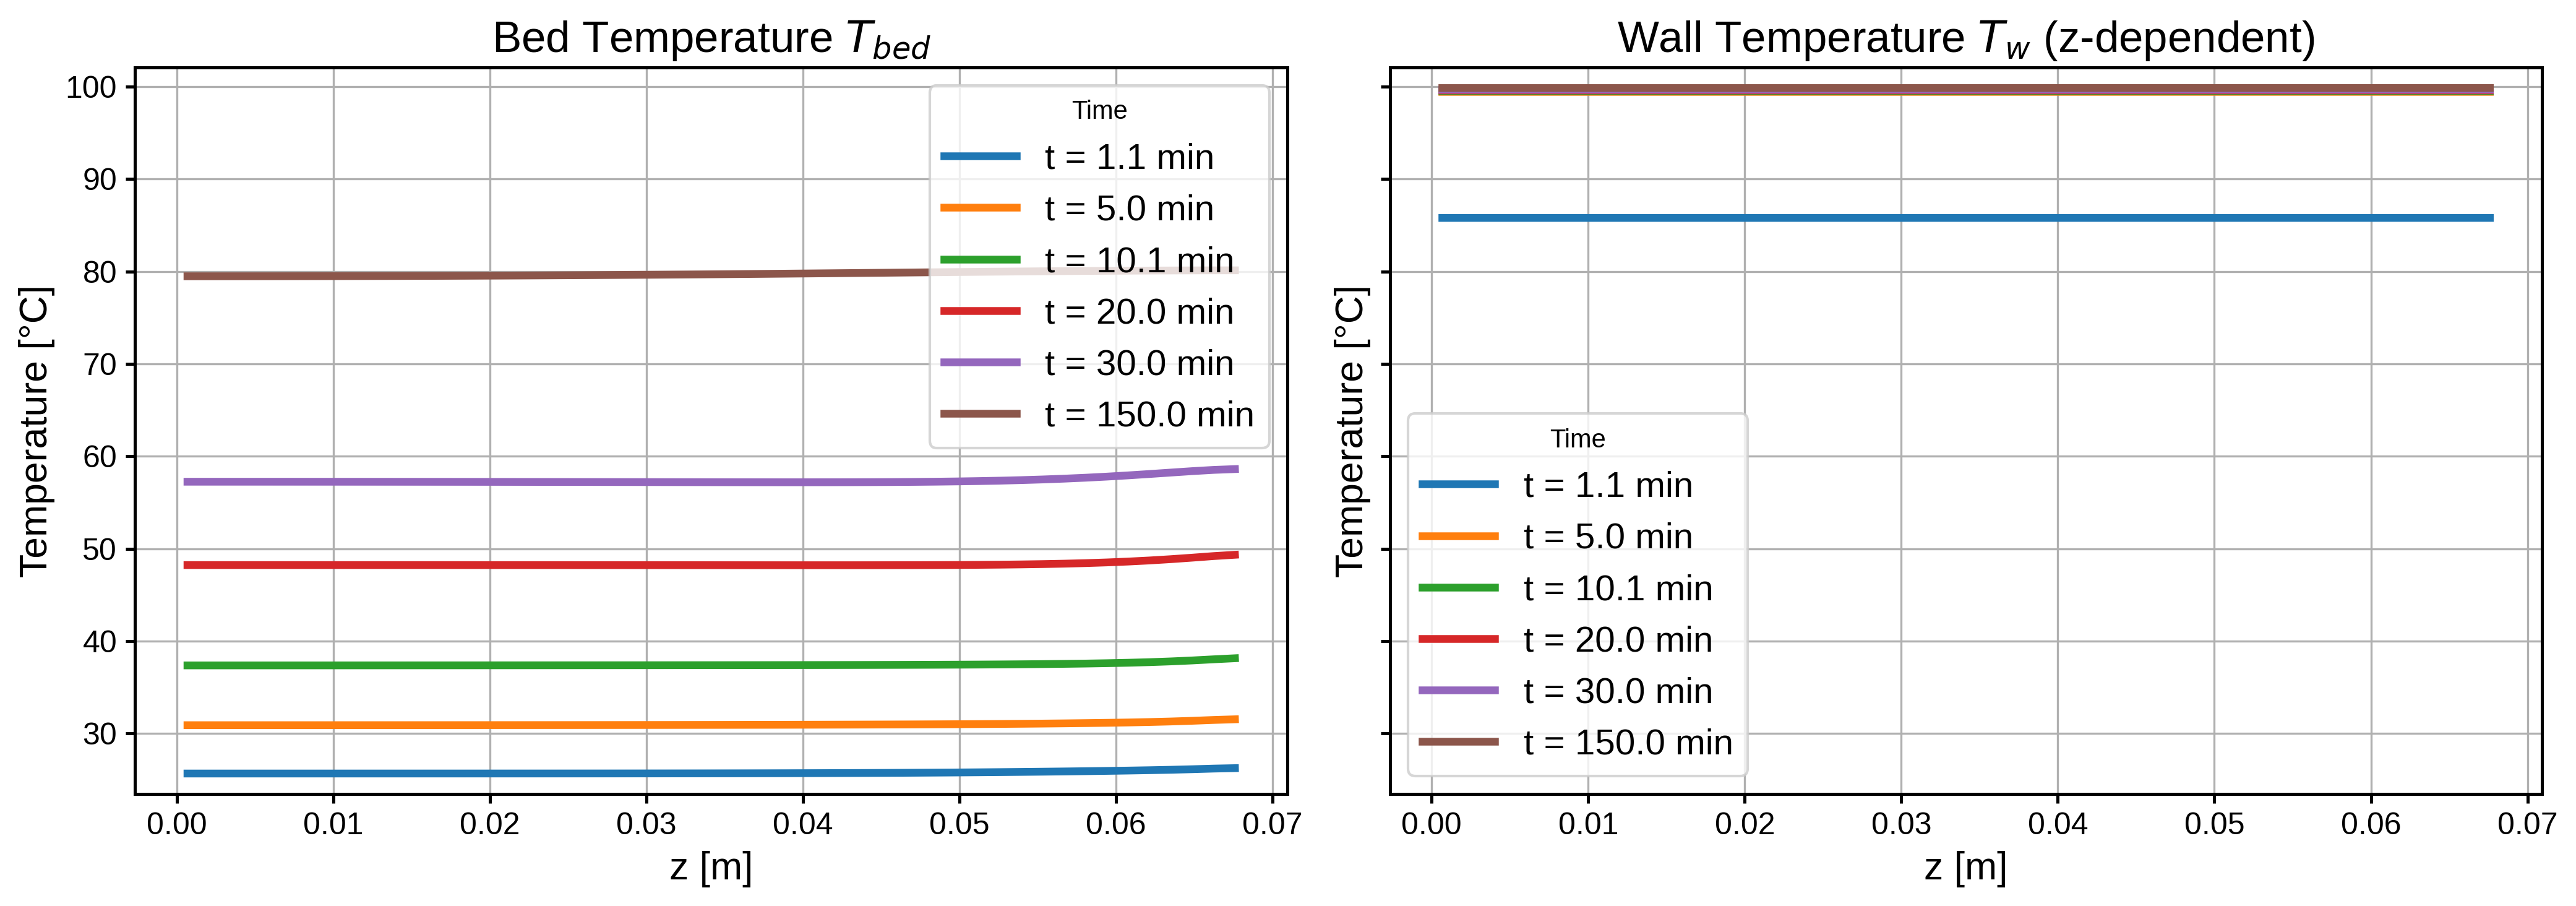

In [6]:
# The 1D model at the same times: bed and wall temperature along the column, one line per time
profile = "heat/profiles/internal_1D_profiles/heat_Tbed_Twall_axial_alltimes.png"
display(Image(filename=results["1D"].results_folder / f"cycle_{results['1D'].cycle}" / profile, width=900))

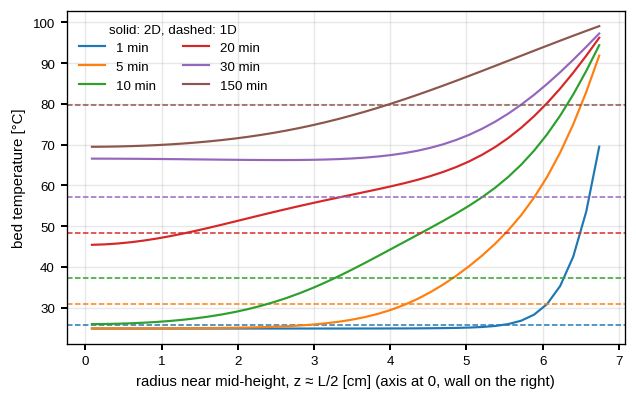

In [7]:
def heat_bed_temperature(result):
    # The `heat` step of the reported cycle: bed temperature [°C] (nz, nr, nt), saved times [min], radius [cm]
    # (sol.pkl is a Python pickle: open only run folders you trust, see tutorial 06)
    with open(result.results_folder / f"cycle_{result.cycle}" / "heat" / "sol.pkl", "rb") as stream:
        solution = pickle.load(stream)
    view, extra = saved_solution_view(solution), solution["extra"]
    r_cm = np.asarray(extra["r_c"]) * extra["R_bed"] * 100
    return view.field("T_bed") - 273.15, np.asarray(view.time_s) / 60, r_cm


T_2d, t_2d, r_cm = heat_bed_temperature(results["2D"])
T_1d, t_1d, _ = heat_bed_temperature(results["1D"])

# Near mid-height (the cell at z ≈ L/2), at the times of the map: 2D across the radius (solid), 1D one value (dashed).
# A small style of its own: the step plots of a run change matplotlib's defaults.
style = {"font.size": 9, "axes.labelsize": 9, "legend.fontsize": 8, "legend.title_fontsize": 8,
         "xtick.labelsize": 8, "ytick.labelsize": 8, "axes.linewidth": 0.8}
with plt.rc_context(style):
    fig, ax = plt.subplots(figsize=(6, 3.6))
    for k, minutes in enumerate(snapshot_times["heat"]["T_bed"]["times"]):
        i2, i1 = np.abs(t_2d - minutes).argmin(), np.abs(t_1d - minutes).argmin()
        ax.plot(r_cm, T_2d[T_2d.shape[0] // 2, :, i2], color=f"C{k}", linewidth=1.3, label=f"{t_2d[i2]:.0f} min")
        ax.axhline(T_1d[T_1d.shape[0] // 2, 0, i1], color=f"C{k}", linewidth=0.9, linestyle="--")
    ax.set_xlabel("radius near mid-height, z ≈ L/2 [cm] (axis at 0, wall on the right)")
    ax.set_ylabel("bed temperature [°C]")
    ax.legend(title="solid: 2D, dashed: 1D", ncol=2, frameon=False, loc="upper left")
    ax.grid(alpha=0.3)
    plt.show()

What the map and the profiles show:
- **2D**: the heat enters at the wall (on the right of each map).
  - In the first minutes only a thin layer next to the wall is hot; the axis stays cold much longer.
  - That hot layer releases its CO2 early, while the gas of `heat` is still vented: that CO2 is lost.
  - At the end of `heat` the wall layer is near the jacket temperature, the axis still around 70 °C.
- **1D**: the model has one temperature per height: the heat from the wall is spread at once over the whole cross-section.
  - The bed warms more evenly: its coldest point ends about 10 °C warmer than the 2D axis.
  - But nowhere gets as hot as the 2D wall layer, so less CO2 leaves before the product is collected.

The gap depends on the geometry:
- this column is short and wide (L/D = 1/2), so heat has a long way from the wall to the axis;
- in a slender column the 1D and 2D models come closer;
- try it with `geometry.aspect_ratio` on top of the case file!

The hot wall layer has a second consequence.

Every CSS run checks whether any point of the bed was above 90 °C while its gas still held oxygen.\
That is the condition in which amine sorbents degrade ([Tutorial 03](03_css_tvsa.ipynb)):

In [8]:
# Read the oxygen check of each run: one row per model
checks = {}
for name, result in results.items():
    check = pd.read_csv(result.results_folder / "kpis" / "csv" / "process" / "oxygen_hot_bed_check.csv")
    checks[name] = check.iloc[0]
pd.DataFrame(checks).T

,condition_met,step,point,time_s
2D,True,heat,"z_index=49,r_index=39 (z=0.99,r=0.9875)",198.198198
1D,False,NaN,NaN,NaN
"2D, channeling",True,heat,"z_index=48,r_index=39 (z=0.97,r=0.9875)",207.207207


What the check tells us:
- **Both 2D runs** flag the cell next to the wall at the outlet end, a few minutes into `heat`.
- **The 1D run** does not:
  - during `heat` its averaged cross-section stays below 90 °C (at most about 80 °C);
  - by the time it passes 90 °C in `s_des`, the oxygen is gone.

A 1D model cannot see the hot layer at the wall.

## Wall channeling

What is it?
- Particles pack more loosely against a flat wall.
- So the voidage rises in the last few particle diameters before the wall.
- With `wall-channeling-reduced`, the gas finds less resistance there and flows faster.

The CO2 loading during adsorption shows it:
- without channeling, the front moves up the column as a flat line;
- with channeling, it runs ahead next to the wall.

2D


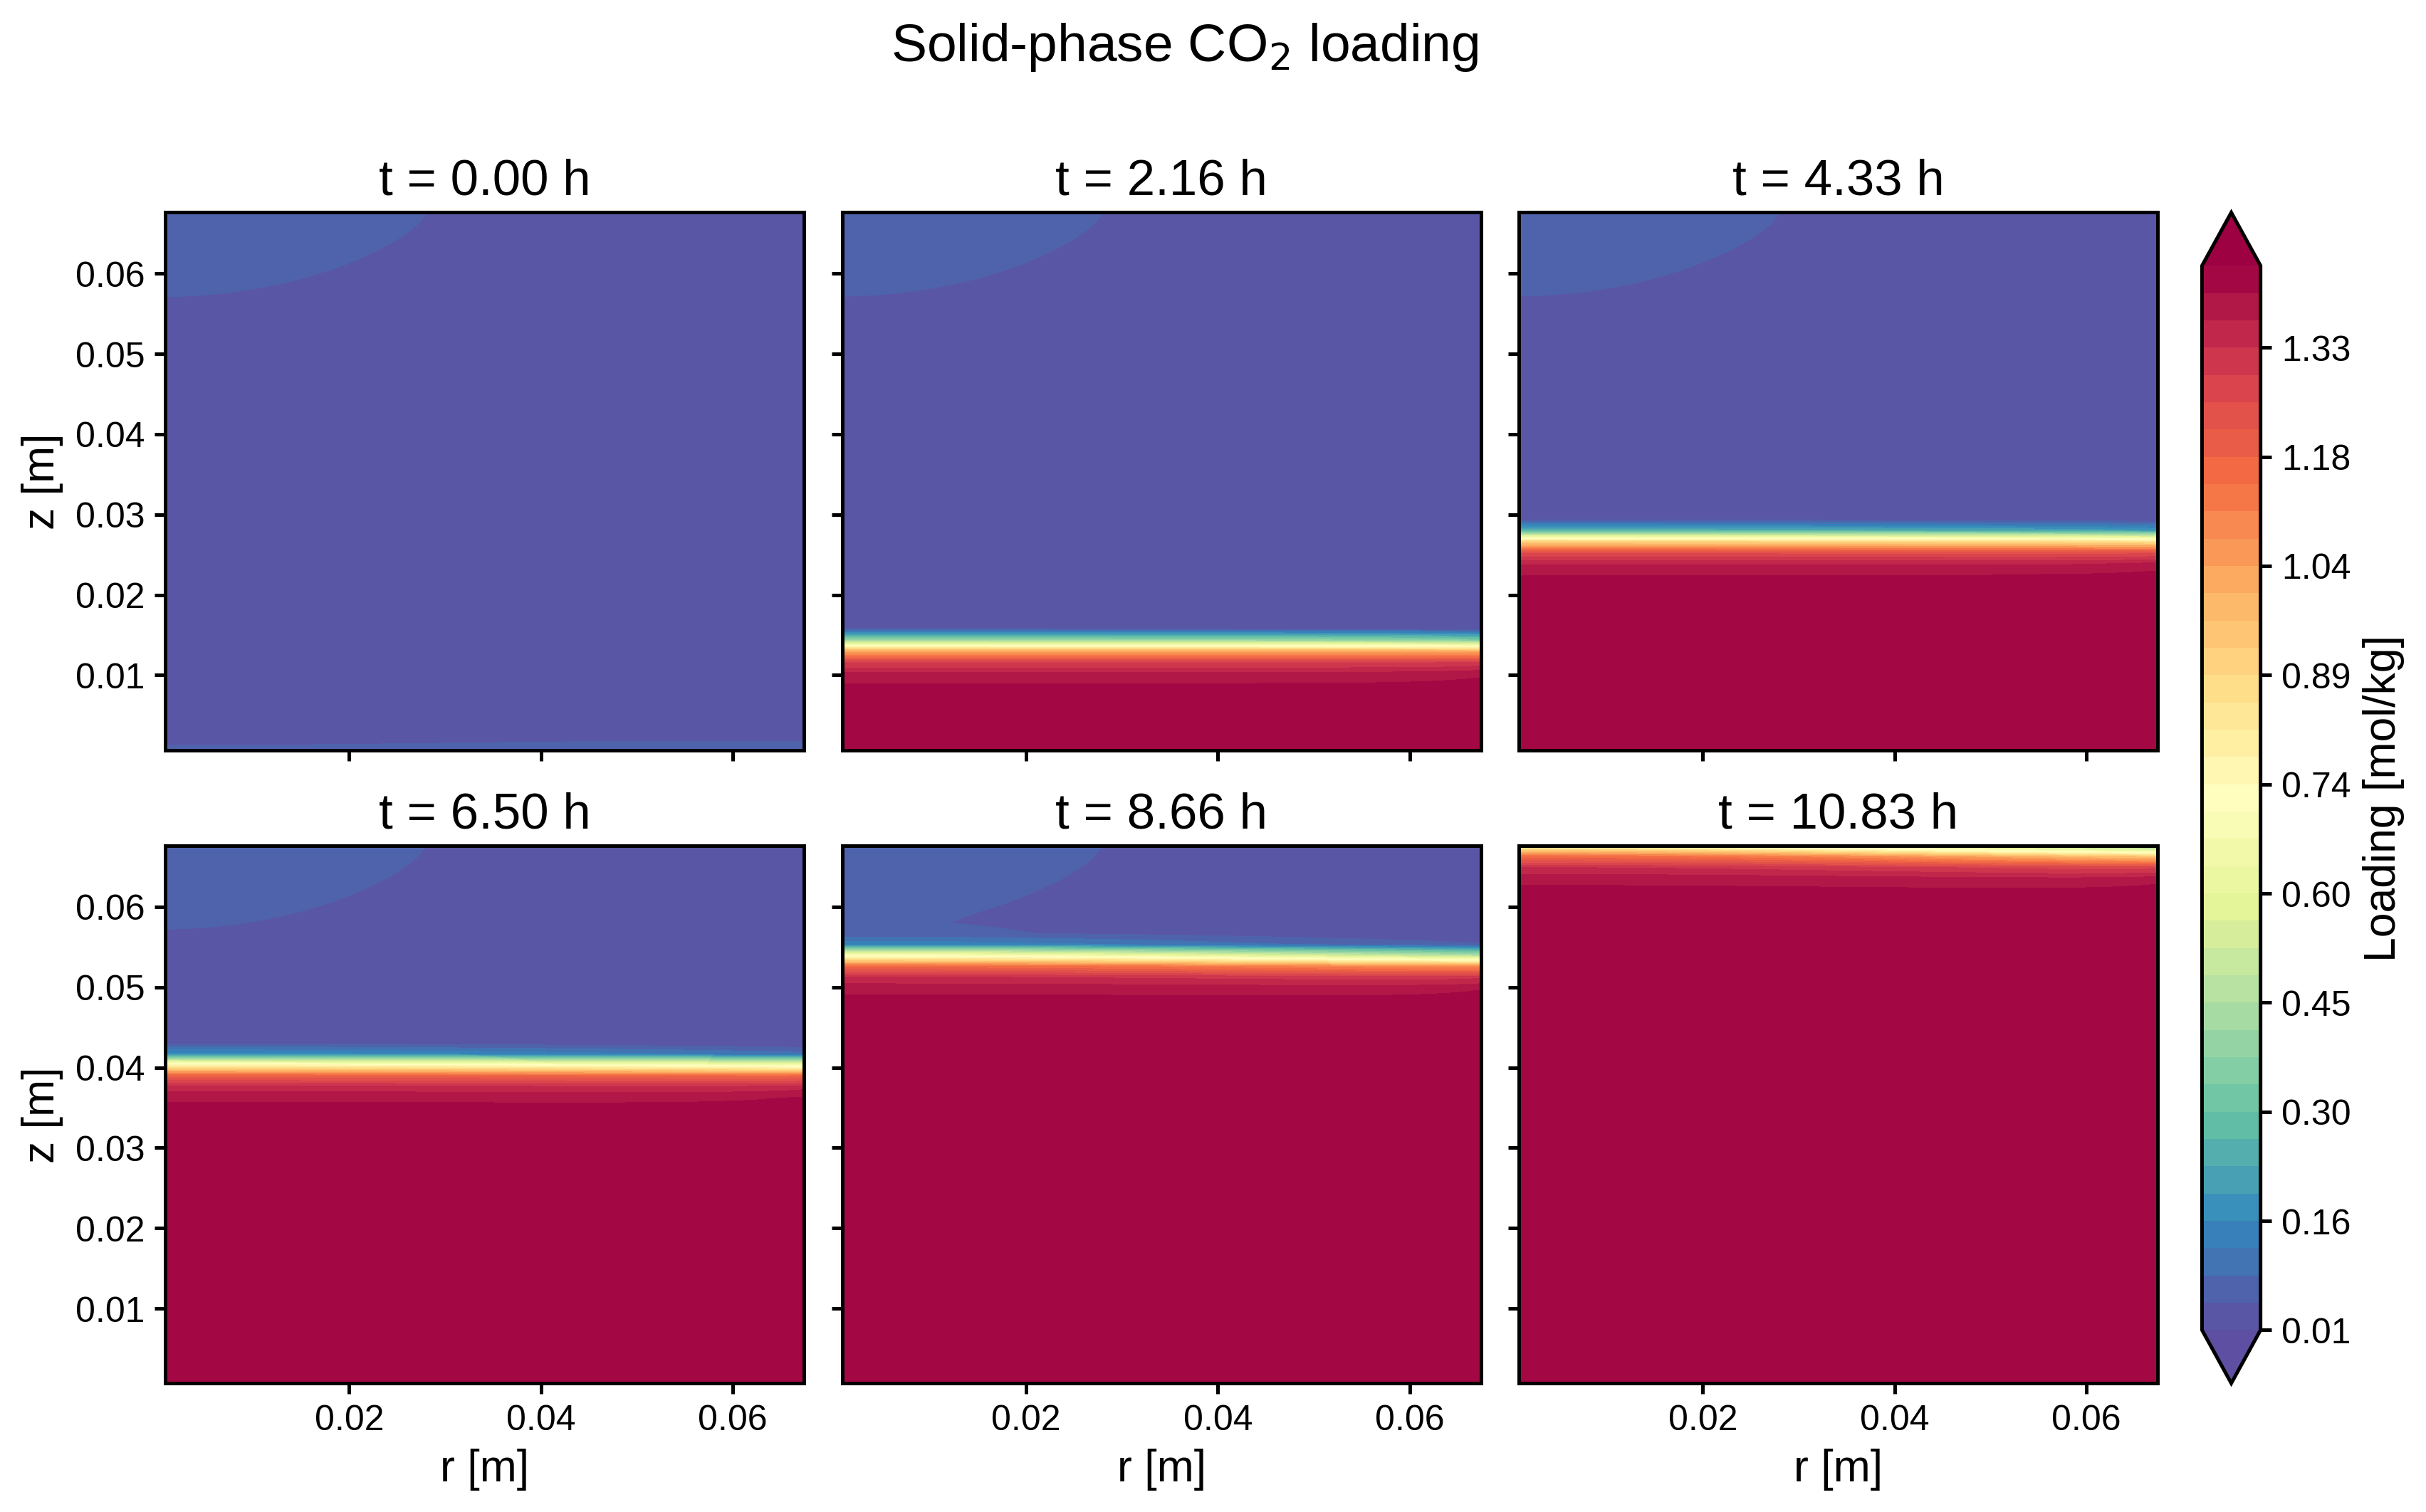

2D, channeling


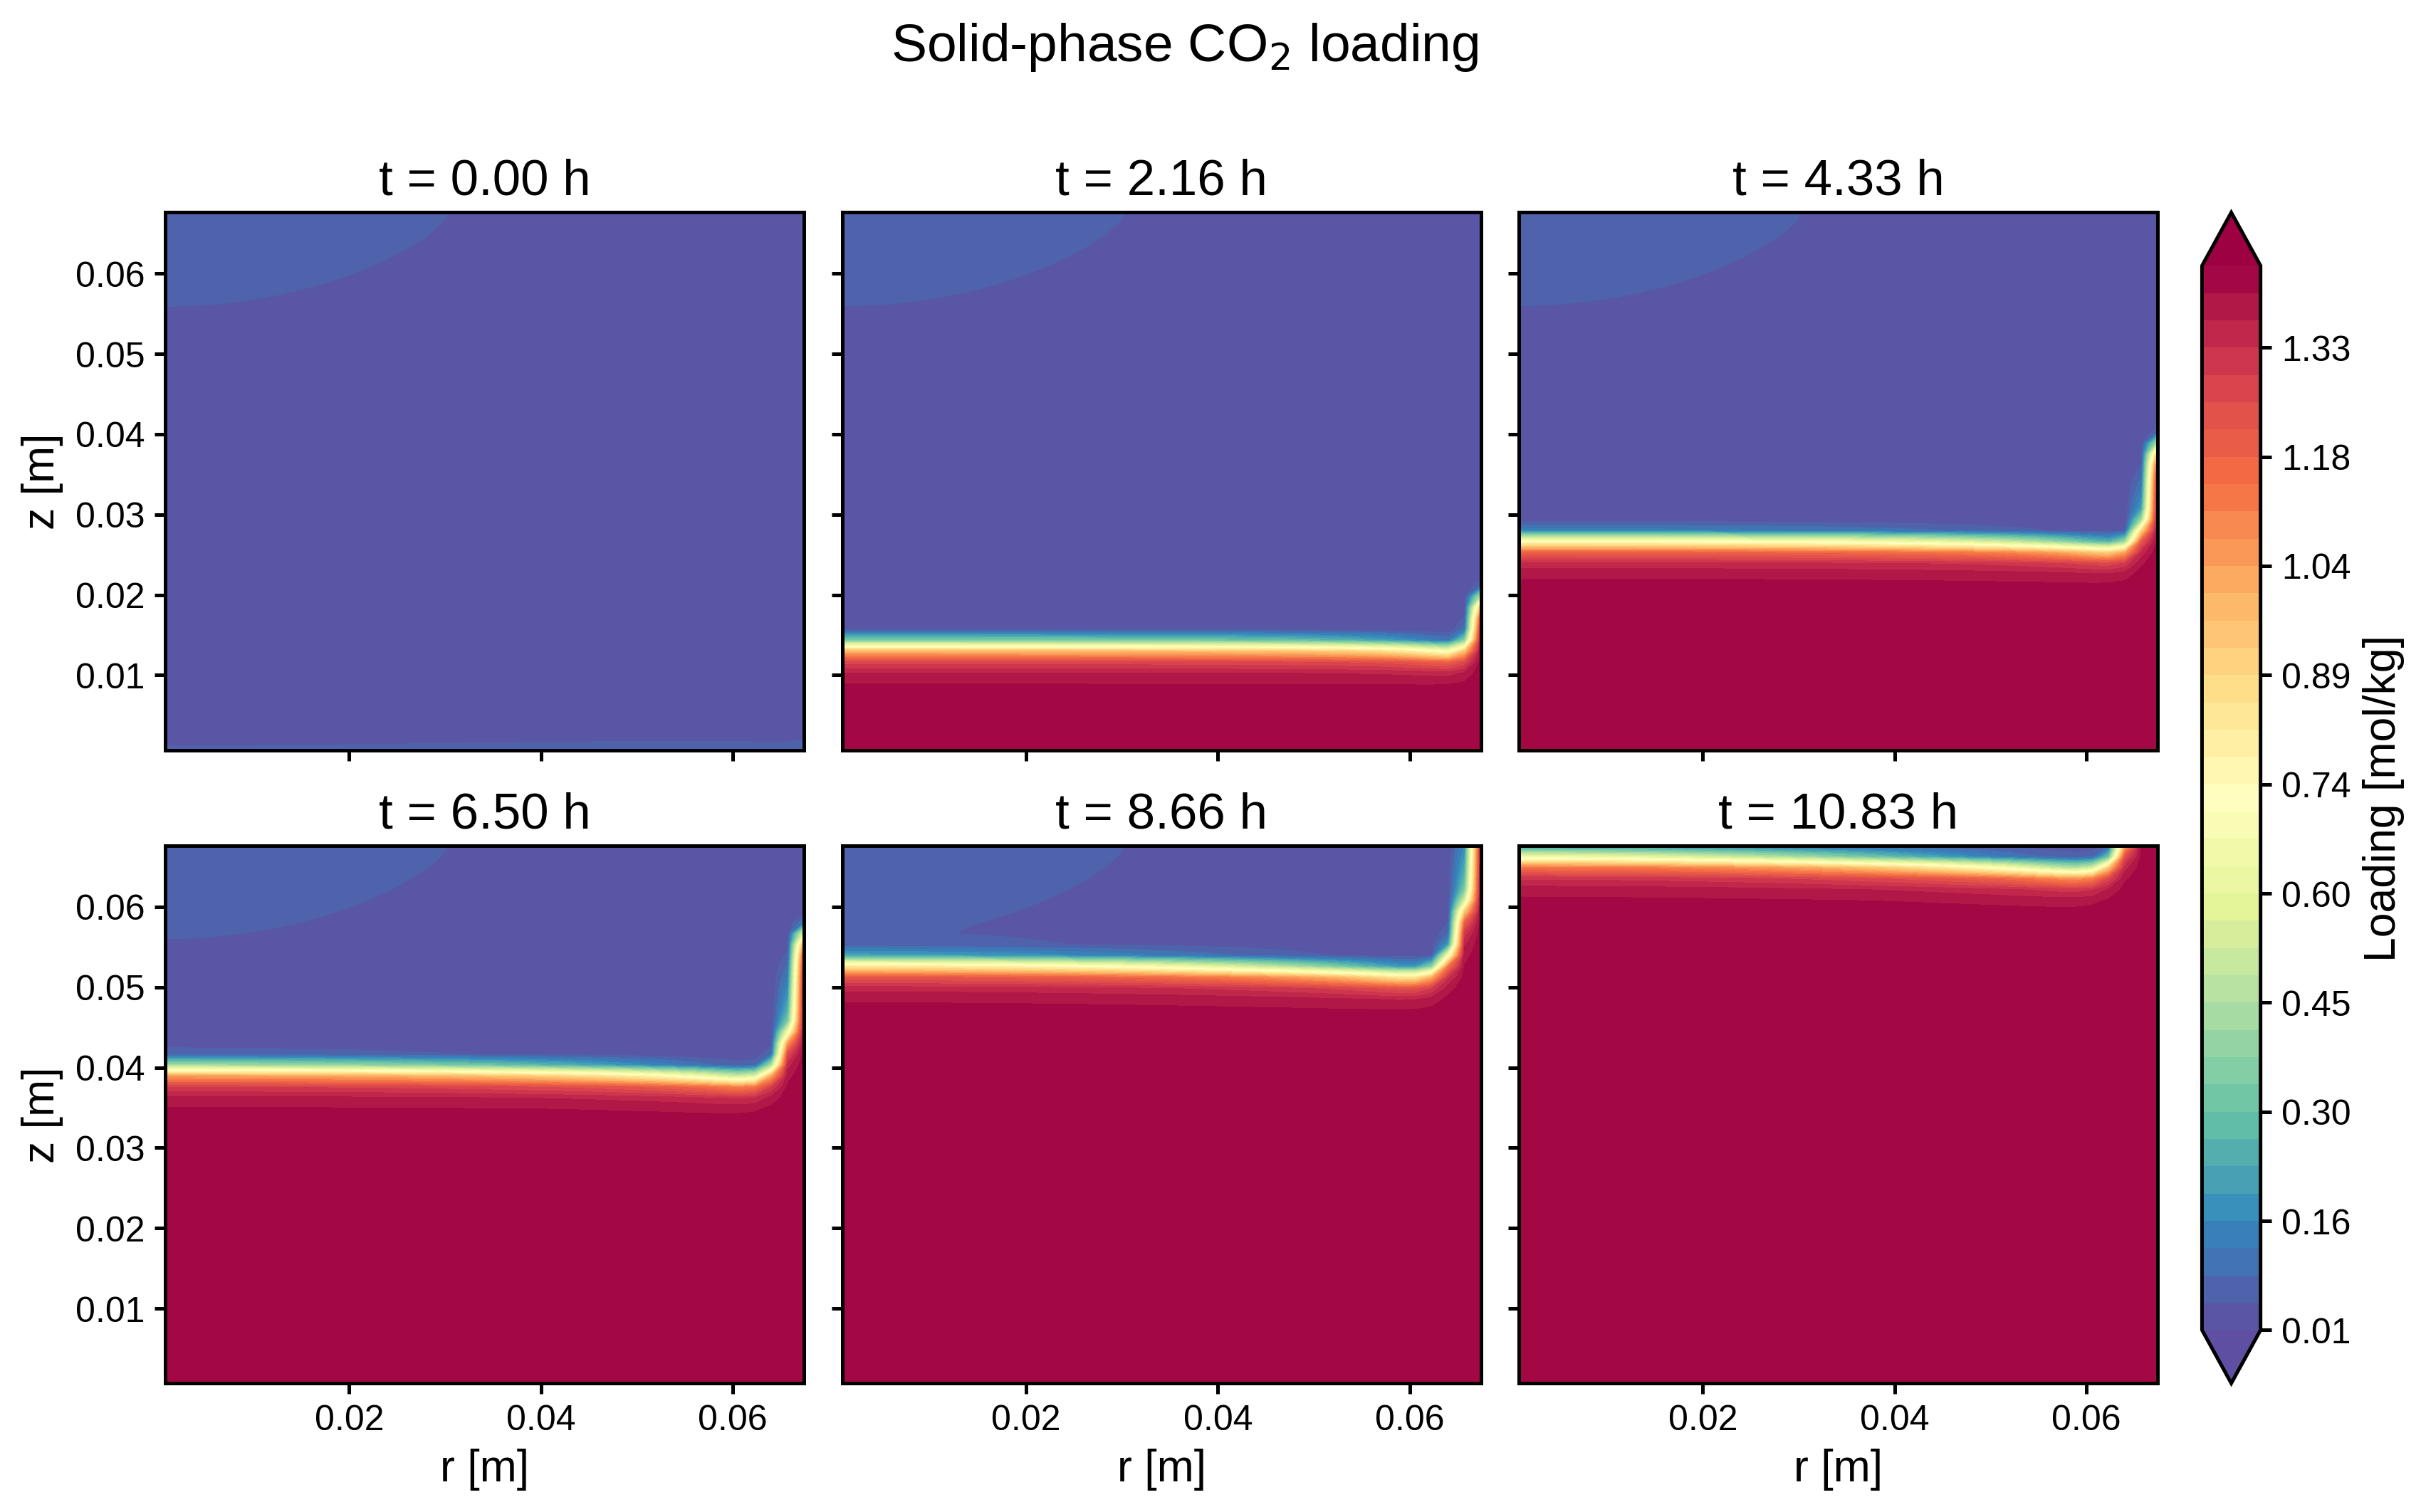

In [9]:
# CO2 loading during ads, without and with channeling
loading_map = "ads/profiles/internal_2D_profiles/ads_qCO2_2D_snapshots.png"
for name in ["2D", "2D, channeling"]:
    print(name)
    display(Image(filename=results[name].results_folder / f"cycle_{results[name].cycle}" / loading_map, width=700))

Here the effect on the KPIs is small:
- below 1 % on productivity and equivalent work;
- against 12 to 13 % between 1D and 2D.

Why so small?
- The column is 270 particle diameters wide, so the loose layer at the wall holds a small share of the bed.
- On this grid one radial cell is 1.7 mm, about 3.4 particle diameters:\
  the looser packing next to the wall (a few particle diameters, de Klerk's profile) spans only one or two cells.
- So the grid resolution can change the size of the effect: the numbers here show its direction (this is not a grid study).

Channeling matters in narrow columns.\
[Tutorial 06](06_breakthrough_validation.ipynb) reproduces the validation of the pyDAC paper,
a breakthrough experiment of Zanco et al. (2022) in a column 40 particles wide,\
where channeling is needed to match the measured temperatures.

## Disk use

With `keep_only_final_cycle`, each run keeps one cycle.\
A 1D run is more than ten times smaller than a 2D one:

In [10]:
def size_mb(folder):
    # Total size of the files in a folder, in MB
    return sum(path.stat().st_size for path in folder.rglob("*") if path.is_file()) / 1e6


# Size of each run folder
for name, result in results.items():
    print(f"{name:15s} {size_mb(result.folder):6.0f} MB")

2D                 727 MB
1D                  54 MB
2D, channeling     727 MB


## The same from the terminal

Run these from the folder of this notebook:

```bash
# 2D
pydac css --config ../cases/04_1d_vs_2d.json --snapshot-times '{"heat": {"T_bed": {"times": [1, 5, 10, 20, 30, 150], "unit": "min"}}}' --overwrite

# 1D: one setting
pydac css --config ../cases/04_1d_vs_2d.json --set grid.nr=1 --snapshot-times '{"heat": {"T_bed": {"times": [1, 5, 10, 20, 30, 150], "unit": "min"}}}' --overwrite

# 2D with channeling: one setting
pydac css --config ../cases/04_1d_vs_2d.json --set bed.design.flow_model=wall-channeling-reduced --snapshot-times '{"heat": {"T_bed": {"times": [1, 5, 10, 20, 30, 150], "unit": "min"}}}' --overwrite
```

Each run writes its KPI report into its own `kpis/` folder.

**Previous:** [Tutorial 03: A cycle at its periodic state](03_css_tvsa.ipynb).\
**Next:** [Tutorial 05: An optimization campaign](05_nsga2_trial.ipynb).